# How boundary loops preserve distance

Clusterising the merge region of a $d=3$ ZZ surgery (`prepare_cluster_region`, then `RealisedSED.hybrid`) drops the $\bar X\bar X$ sector to distance 2. Looping the region's boundary (`loop_boundary`) restores distance 3.

This notebook zooms in on one boundary generator to show where the lost distance comes from and how the loop gets it back. It then repeats the story for the column of boundary generators on the other side of the seam:

1. **Split.** Boundary splitting adds an edge $f$ between the generator's inside and outside halves. Every web with odd non-matching parity over the inside legs now crosses $f$.
2. **Hadamard fusion.** Dualising the inside half puts an H node on $f$, which becomes an `XZ`/`ZX` fusion. One fault on $f$ fires exactly what a $Z$ on *both* seam legs fires, and flips the logical just as that pair does. That pair is a vertical hook along the seam, the direction of the minimum-weight $Z$ string.
3. **Loop.** Looping $f$ moves the two seam legs onto different spiders. Every crossing edge now carries one seam leg, and a fault on it also fires the new loop web.

**Fault model.** A fault is a single Pauli on one edge of the closed diagram. It fires the detectors whose web anticommutes with it on that edge, and it flips the observables that anticommute in the same way. This is the edge-level picture. The circuit-level distances at the end, from stim, give the same 2 → 3.

In [1]:
%matplotlib inline
import collections

import matplotlib.pyplot as plt
import numpy as np

from dizx.circuit_extractor import to_stim
from dizx.realisation import RealisedSED
from dizx.schedules import RotatedSurfaceCodeSchedule
from dizx.surgery import two_patch_surgery
from dizx.transformations import cut_edges, loop_boundary, prepare_cluster_region, split_boundary
from dizx.zx_diagram import PAULI_BITS, NodeType, web_matrix

s = two_patch_surgery(3, "ZZ")
S0 = s.merge_region()                                 # seam spiders + merge-round generators on them
split_sed = split_boundary(s.sed, S0)                 # step 1 only
hsed, S = prepare_cluster_region(s.sed, S0)           # step 1 + dualise (step 2)
lsed, SL, rungs = loop_boundary(hsed, S)              # step 3

plain = RealisedSED.hybrid(hsed, S)
looped = RealisedSED.hybrid(lsed, SL, {r: "bell" for r in rungs})
exp_plain, exp_looped = s.experiment("X", realised=plain), s.experiment("X", realised=looped)

# prepare_cluster_region's split is exactly split_boundary's, so split_sed is its intermediate.
assert prepare_cluster_region(split_sed, S0)[0].edges == hsed.edges
print("seam qubits", s.seam, "| merge rounds", list(s.merge_rounds))
print("boundary edges", len(cut_edges(hsed, S)), "| looped", len(rungs) // 2)

seam qubits [(3, 0), (3, 1), (3, 2)] | merge rounds [3, 4, 5, 6]
boundary edges 22 | looped 14


## The generator we zoom in on

The seam is the column $x = 3$. The region $S$ holds the seam's spiders and the merge-round generators on them, so its boundary runs between the left patch's column $x = 2$ and the seam.

`g` is a merge-round $Z$ check (an X spider) from the first merge round. Two of its legs go to seam qubits (inside $S$) and two to left-patch qubits (outside).

In [2]:
r0 = s.merge_rounds[0]
g = ("gen", r0, 10)
G_POS = np.asarray(s.sed.positions[g], float)
legs = {u[-1]: u in S0 for u in s.sed.graph.neighbors(g)}
print(g, s.sed.types[g], "at", tuple(G_POS))
print("legs (qubit: inside S)", legs)
assert s.sed.types[g] is NodeType.X and sorted(legs.values()) == [False, False, True, True]

D_IDX, L_IDX = 84, 2      # the detector and the logical (X̄X̄ -> X̄X̄) that the story is about
print("logical", s.sed.logicals[L_IDX].boundary())

('gen', 3, 10) NodeType.X at (np.float64(2.5), np.float64(0.5), np.float64(6.0))
legs (qubit: inside S) {(2, 0): False, (3, 0): True, (2, 1): False, (3, 1): True}
logical ('XXXIIIIIIXXXIIIIII', 'XXXIIIIIIXXXIIIIII')


In [3]:
# -- helpers -------------------------------------------------------------------

def edge(d, u, v):
    # The edge leaving u towards v: direct, or into the H node between them.
    for e in d.graph.edges(u, keys=True):
        if e[1] == v:
            return e
    for e in d.graph.edges(u, keys=True):
        if d.types[e[1]] is NodeType.H and v in d.graph.neighbors(e[1]):
            return e
    raise KeyError((u, v))


def wire(d, q, r=r0):
    # The wire leg of qubit q at its round-r Z spider (a Z here is a Z on the qubit).
    return edge(d, ("data", r, "Z", q), ("data", r, "X", q))


def syndrome(exp, faults):
    # (fired detectors, flipped observables) of a set of (edge, Pauli) faults.
    n = exp.n_edges
    D = web_matrix(exp.detectors, n).toarray().astype(int)
    O = web_matrix(exp.observables, n).toarray().astype(int)
    sd, so = np.zeros(len(D), int), np.zeros(len(O), int)
    for e, p in faults:
        i = exp.edge_index(e)
        a, b = PAULI_BITS[p]
        sd ^= (D[:, n + i] * a + D[:, i] * b) % 2   # X anticommutes with z, Z with x
        so ^= (O[:, n + i] * a + O[:, i] * b) % 2
    return tuple(np.flatnonzero(sd).tolist()), bool(so.any())


def ambiguous_classes(exp):
    # Syndromes shared by single faults with different logical action (weight-2 logicals).
    n = exp.n_edges
    D = web_matrix(exp.detectors, n).toarray().astype(int)
    O = web_matrix(exp.observables, n).toarray().astype(int)
    by = collections.defaultdict(lambda: collections.defaultdict(list))
    for i in range(n):
        for p, (a, b) in (("X", (1, 0)), ("Z", (0, 1)), ("Y", (1, 1))):
            sd = (D[:, n + i] * a + D[:, i] * b) % 2
            so = (O[:, n + i] * a + O[:, i] * b) % 2
            assert sd.any() or not so.any(), "undetectable weight-1 logical"
            if sd.any():
                by[sd.tobytes()][so.tobytes()].append((exp.edges[i], p))
    return [v for v in by.values() if len(v) > 1]


WEB = {"X": "tab:green", "Z": "tab:red", "Y": "tab:purple"}
NODE = {NodeType.Z: "tab:green", NodeType.X: "tab:red", NodeType.P: "black"}
BOX = ((1.75, 3.35), (-0.35, 1.35))            # (x range, y range) around g


def zoom(d, web=None, faults=(), ax=None, title=None, box=BOX, labels=None, bold=(), region=None):
    # The plane of g's round, seen from above, in the box (x range, y range). Edges in the
    # plane are drawn; an edge leaving it (a time step or a measurement) is a triangle at its
    # in-plane end: up (later) or down (earlier), coloured by the web. Stars mark faults.
    pos = {v: np.asarray(p, float) for v, p in d.positions.items()}
    in_plane = lambda v: abs(pos[v][2] - G_POS[2]) < 0.3
    near = lambda v: (box[0][0] - 0.5 <= pos[v][0] <= box[0][1] + 0.5
                      and box[1][0] - 0.5 <= pos[v][1] <= box[1][1] + 0.5)
    ax = ax or plt.figure(figsize=(5, 5)).add_subplot()
    thick = {d.edge_index(e) for e in bold}
    sup = web.support() if web is not None else {}
    seen = collections.Counter()
    where = {}                                     # edge index -> point to put a fault star
    for i, e in enumerate(d.edges):
        u, v, _ = e
        if not (near(u) or near(v)) or not (in_plane(u) or in_plane(v)):
            continue
        p = sup.get(e, "I")
        if in_plane(u) and in_plane(v):
            k = seen[frozenset((u, v))]
            seen[frozenset((u, v))] += 1
            a, b = pos[u][:2], pos[v][:2]
            pts = np.array([a, b])
            if k:
                n = np.array([-(b - a)[1], (b - a)[0]])
                pts = np.array([a, (a + b) / 2 + 0.18 * n * (1 if k % 2 else -1), b])
            h = NodeType.H in (d.types[u], d.types[v])
            ax.plot(*pts.T, color="tab:blue" if h else "0.15" if i in thick else "0.6",
                    ls="--" if h else "-", lw=4 if i in thick else 1.1, zorder=1)
            if p != "I":
                ax.plot(*pts.T, color=WEB[p], lw=7 if i in thick else 5, alpha=0.8, zorder=2,
                        solid_capstyle="round")
            where[i] = pts.mean(axis=0) if len(pts) == 2 else pts[1]
        else:
            a, b = (u, v) if in_plane(u) else (v, u)
            up = pos[b][2] > pos[a][2]
            q = pos[a][:2] + (np.array([0.045, 0.06]) if up else np.array([-0.045, -0.06]))
            ax.scatter(*q, marker="^" if up else "v", s=70 if p != "I" else 18,
                       color=WEB.get(p, "0.6"), zorder=3)
            where[i] = q
    for v, t in d.types.items():
        if not (in_plane(v) and near(v)):
            continue
        if region is not None and v in region and t in NODE:
            ax.scatter(*pos[v][:2], s=300, color="lightskyblue", alpha=0.5, zorder=3, lw=0)
        if t in NODE:
            ax.scatter(*pos[v][:2], s=80, color=NODE[t], edgecolors="black", lw=0.6, zorder=4)
        elif t is NodeType.H:
            ax.scatter(*pos[v][:2], marker="s", s=22, color="gold", edgecolors="black", lw=0.4, zorder=4)
    for e, pauli in faults:
        q = where[d.edge_index(e)]
        ax.scatter(*q, marker="*", s=420, color="black", zorder=6)
        ax.annotate(pauli, q, xytext=(7, 7), textcoords="offset points", fontsize=13, weight="bold", zorder=7)
    for v, text in (labels or {}).items():
        if v in pos and in_plane(v):
            ax.annotate(text, pos[v][:2], xytext=(6, -13), textcoords="offset points", fontsize=9, zorder=7)
    ax.set_xlim(*box[0]); ax.set_ylim(*box[1])
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=10)
    return ax


def labels_for(d, names=None):
    # names: generator -> short name; its halves get name', ℓ(name), ℓ(name').
    out = {}
    for x, n in (names or {g: "g"}).items():
        out |= {x: n, ("split", x): n + "'", ("loop", x): f"ℓ({n})", ("loop", ("split", x)): f"ℓ({n}')"}
    out |= {("data", r0, "Z", (x, y)): f"{(x, y)}" for x in (2, 3, 4) for y in (0, 1, 2)}
    return out


def row(n, w=5.0, h=5.0):
    fig, axes = plt.subplots(1, n, figsize=(w * n, h))
    return fig, list(np.atleast_1d(axes))

**How to read the pictures.** Green and red dots are Z and X spiders, and gold squares are H nodes. Dashed blue lines are Hadamard edges, and bold lines are fusions. A web's support is drawn thick: green for $X$, red for $Z$, purple for $Y$. Stars mark faults. Each picture is the plane of `g`'s round seen from above. An edge leaving the plane (a time step of a qubit wire, or a measurement) is a triangle at its in-plane end, ▲ for later and ▼ for earlier, enlarged and coloured when the web is on it. The labels name `g`, its halves, and the round's data spiders by qubit.

## Step 0: the generator before the split

In the original SED, two webs pass through `g`:

- detector $D$ (`D_IDX`), one of the detectors through `g`, picked because it is the one the hook below fires;
- the logical web $\bar X\bar X \to \bar X\bar X$.

The relevant errors are $Z$s on the seam qubits at this round. $Z_{(3,0)}Z_{(3,1)}Z_{(3,2)}$ is a vertical $Z$ string along the seam. It is undetectable and flips $\bar X\bar X$: a minimum-weight logical. No single fault is a pair of its qubits, so it costs three faults.

Z(3,0)                 fires (99,), flips X̄X̄: True
Z(3,1)                 fires (84, 99), flips X̄X̄: False
Z(3,2)                 fires (84,), flips X̄X̄: False
Z(3,0) Z(3,1)          fires (84,), flips X̄X̄: True
Z(3,0) Z(3,1) Z(3,2)   fires (), flips X̄X̄: True
weight-2 logicals in the unsplit circuit-based experiment: 0


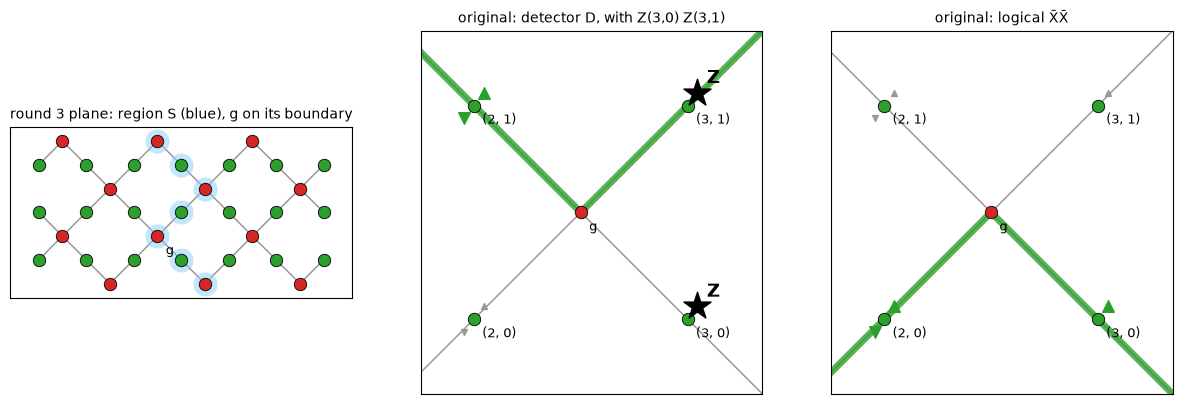

In [4]:
cb = s.experiment("X")            # circuit-based realisation of the unsplit SED, for comparison
Zs = {q: (wire(cb, q), "Z") for q in [(3, 0), (3, 1), (3, 2)]}
for name, fs in [("Z(3,0)", [Zs[3, 0]]), ("Z(3,1)", [Zs[3, 1]]), ("Z(3,2)", [Zs[3, 2]]),
                 ("Z(3,0) Z(3,1)", [Zs[3, 0], Zs[3, 1]]), ("Z(3,0) Z(3,1) Z(3,2)", list(Zs.values()))]:
    print(f"{name:22s} fires {syndrome(cb, fs)[0]}, flips X̄X̄: {syndrome(cb, fs)[1]}")
assert syndrome(cb, list(Zs.values())) == ((), True)
print("weight-2 logicals in the unsplit circuit-based experiment:", len(ambiguous_classes(cb)))

fig, (o, a, b) = row(3)
zoom(s.sed, ax=o, region=S0, box=((-0.6, 6.6), (-0.8, 2.8)), labels={g: "g"},
     title=f"round {r0} plane: region S (blue), g on its boundary")
zoom(s.sed, s.sed.detectors[D_IDX], [Zs[3, 0], Zs[3, 1]], ax=a, labels=labels_for(s.sed),
     title="original: detector D, with Z(3,0) Z(3,1)")
zoom(s.sed, s.sed.logicals[L_IDX], ax=b, labels=labels_for(s.sed), title="original: logical X̄X̄")
plt.show()

## Step 1: the split

`split_boundary` splits `g` into an inside half `g` (seam legs $A$) and an outside half `g'` (patch legs $B$), joined by one new edge $f$. The split rule (`docs/transformations.md`) puts on $f$:

- the matching component ($z$ for an X spider), which is constant over `g`'s legs;
- the non-matching component ($x$), equal to the **parity over $A$**.

Both $D$ and the logical have odd $x$-parity over the two seam legs, so both now cross $f$ with an $X$. A $Z$ fault on $f$ anticommutes with both. By the X spider's rule, $Z$ on one leg equals $Z$ on all the other legs of a half: the fault is $Z$ on all of $A$, which is $Z_{(3,0)}Z_{(3,1)}$ (or $Z$ on all of $B$, an equivalent pair on the left patch).

D        on f: X   on g's legs: (3, 0):I, (3, 1):X, (2, 0):I, (2, 1):X
logical  on f: X   on g's legs: (3, 0):X, (3, 1):I, (2, 0):X, (2, 1):I


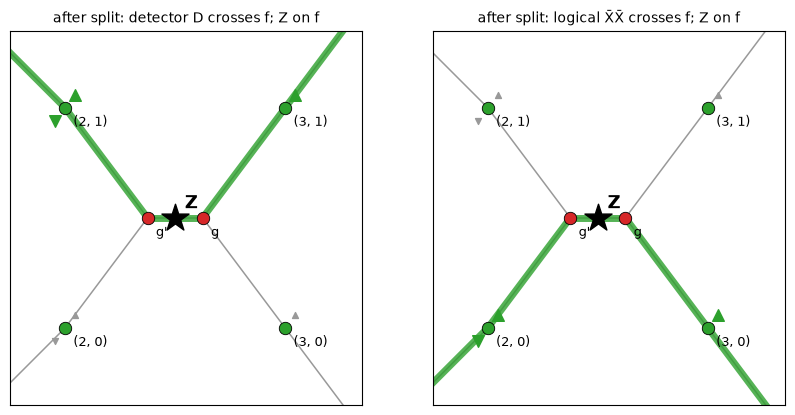

In [5]:
f = edge(split_sed, g, ("split", g))
for name, w in [("D", split_sed.detectors[D_IDX]), ("logical", split_sed.logicals[L_IDX])]:
    print(f"{name:8s} on f: {w.pauli(f)}   on g's legs: "
          + ", ".join(f"{u[-1]}:{w.pauli(edge(split_sed, x, u))}" for x in (g, ("split", g))
                      for u in split_sed.graph.neighbors(x) if u[0] == "data"))

fig, axes = row(2)
for ax, (name, w) in zip(axes, [("detector D", split_sed.detectors[D_IDX]),
                                ("logical X̄X̄", split_sed.logicals[L_IDX])]):
    zoom(split_sed, w, [(f, "Z")], ax=ax, labels=labels_for(split_sed),
         title=f"after split: {name} crosses f; Z on f")
plt.show()

## Step 2: the Hadamard fusion

`prepare_cluster_region` then dualises the region's X spiders, so the inside half `g` becomes a Z spider with an H node on each leg. $f$ becomes `g -H- g'`, an opposite-colour edge across the boundary, and `RealisedSED.hybrid` realises it as an `XZ`/`ZX` fusion.

On the `g` side of the H node the labels swap $x \leftrightarrow z$. The $X$ that $D$ and the logical had on $f$ is a $Z$ there, so a single $X$ on that half of $f$ flips both. In measurement terms, this is a flip of the fusion's `ZX` outcome, which lies in both records.

fusion ('XZ', 'ZX') | edge leaving g: (('gen', 3, 10), ('H', ('gen', 3, 10), ('split', ('gen', 3, 10)), 0))
ZX outcome in D's record: True
ZX outcome in the logical's record: True


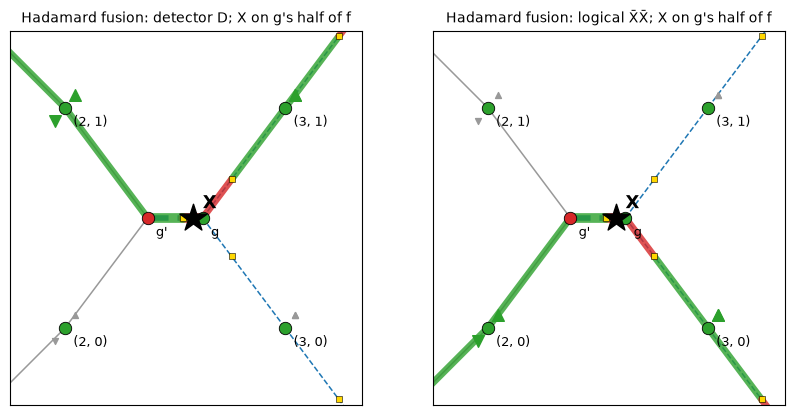

In [6]:
fz = edge(plain, g, ("split", g))
(link,) = [l for l in plain.links if set(l.interaction.ends) == {g, ("split", g)}]
print("fusion", link.ops, "| edge leaving g:", fz[:2])
zx = link.outcomes[1]
print("ZX outcome in D's record:", zx in plain.record(plain.detectors[D_IDX]))
print("ZX outcome in the logical's record:", zx in plain.record(plain.logicals[L_IDX]))

fig, axes = row(2)
for ax, (name, w) in zip(axes, [("detector D", plain.detectors[D_IDX]),
                                ("logical X̄X̄", plain.logicals[L_IDX])]):
    zoom(plain, w, [(fz, "X")], ax=ax, labels=labels_for(plain), bold=[e for l in plain.links
         if l.kind == "fusion" for e in l.interaction.edges], title=f"Hadamard fusion: {name}; X on g's half of f")
plt.show()

## One fault, two qubits' worth of string

In the closed experiment, a single fault on the fusion edge has exactly the syndrome and logical action of $Z_{(3,0)}Z_{(3,1)}$, the vertical hook. $Z_{(3,2)}$ fires the same detector without flipping the logical. Together the two are undetectable and flip $\bar X\bar X$: **a weight-2 logical**.

fusion fault             fires (84,), flips X̄X̄: True
Z(3,0) Z(3,1)            fires (84,), flips X̄X̄: True
Z(3,2)                   fires (84,), flips X̄X̄: False
fusion fault + Z(3,2)    fires (), flips X̄X̄: True


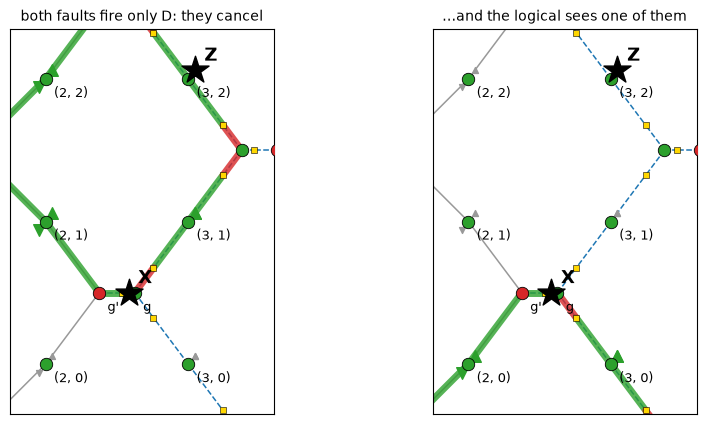

In [7]:
e = exp_plain
fus = (edge(e, g, ("split", g)), "X")
Zp = {q: (wire(e, q), "Z") for q in [(3, 0), (3, 1), (3, 2)]}
rows = [("fusion fault", [fus]), ("Z(3,0) Z(3,1)", [Zp[3, 0], Zp[3, 1]]), ("Z(3,2)", [Zp[3, 2]]),
        ("fusion fault + Z(3,2)", [fus, Zp[3, 2]])]
for name, fs in rows:
    print(f"{name:24s} fires {syndrome(e, fs)[0]}, flips X̄X̄: {syndrome(e, fs)[1]}")
assert syndrome(e, [fus]) == syndrome(e, [Zp[3, 0], Zp[3, 1]]) == ((D_IDX,), True)
assert syndrome(e, [fus, Zp[3, 2]]) == ((), True)

fig, (a, b) = row(2)
zoom(plain, plain.detectors[D_IDX], [(fz, "X"), (wire(plain, (3, 2)), "Z")], ax=a,
     labels=labels_for(plain), box=((1.75, 3.6), (-0.35, 2.35)), title="both faults fire only D: they cancel")
zoom(plain, plain.logicals[L_IDX], [(fz, "X"), (wire(plain, (3, 2)), "Z")], ax=b,
     labels=labels_for(plain), box=((1.75, 3.6), (-0.35, 2.35)), title="…and the logical sees one of them")
plt.show()

This is not special to `g`. At edge level, every syndrome shared by single faults with different logical action (each gives a weight-2 logical) involves a boundary fusion. There are two per merge round, one for each column of boundary $Z$ checks beside the seam (the other column is the next section). The unsplit circuit-based experiment has none.

In [8]:
cut = {frozenset(x[:2]) for x in cut_edges(hsed, S)}
classes = ambiguous_classes(exp_plain)
gens = sorted({u for c in classes for fs in c.values() for (a, b, _), _ in fs
               if frozenset((a, b)) in cut for u in (a, b) if u[0] == "gen"})
print(len(classes), "weight-2 classes; each with a boundary fusion:",
      all(any(frozenset(x[:2]) in cut for fs in c.values() for x, _ in fs) for c in classes))
print("generators whose fusions take part:", gens)

8 weight-2 classes; each with a boundary fusion: True
generators whose fusions take part: [('gen', 3, 7), ('gen', 3, 9), ('gen', 3, 10), ('gen', 3, 12), ('gen', 4, 7), ('gen', 4, 9), ('gen', 4, 10), ('gen', 4, 12), ('gen', 5, 7), ('gen', 5, 9), ('gen', 5, 10), ('gen', 5, 12), ('gen', 6, 7), ('gen', 6, 9), ('gen', 6, 10), ('gen', 6, 12)]


## Step 3: the loop

`loop_boundary` applies `loop_edge(g', g)`. It adds a parallel copy $f'$ of the fusion edge, then splits each end, so the boundary edge becomes a 4-cycle
`g - g' - ℓ(g') - ℓ(g) - g`:

- `g` keeps one seam leg and `ℓ(g)` takes the other;
- the two same-colour rungs `g - ℓ(g)` and `g' - ℓ(g')` are Bell pairs;
- the cut now crosses the loop twice, through two fusions.

The loop web $\ell$ is a new detector around the cycle. Webs are rerouted the short way round it.

No single crossing edge carries the parity over both seam legs any more. A fault on `g`'s fusion is now $Z_{(3,0)}$ plus an $X$ on the rung, and the rung part fires $\ell$. Its syndrome no longer matches $Z_{(3,2)}$, so the weight-2 logical is gone.

loop web ℓ is detector 150
fusion g-g' fault            fires (150,), flips X̄X̄: True
Z(3,0) + X on rung           fires (150,), flips X̄X̄: True
fusion ℓ(g)-ℓ(g') fault      fires (84, 150), flips X̄X̄: False
Z(3,1) + X on rung           fires (84, 150), flips X̄X̄: False
Z(3,2)                       fires (84,), flips X̄X̄: False
fusion g-g' fault + Z(3,2)   fires (84, 150), flips X̄X̄: True
Z(3,0) Z(3,1) Z(3,2)         fires (), flips X̄X̄: True


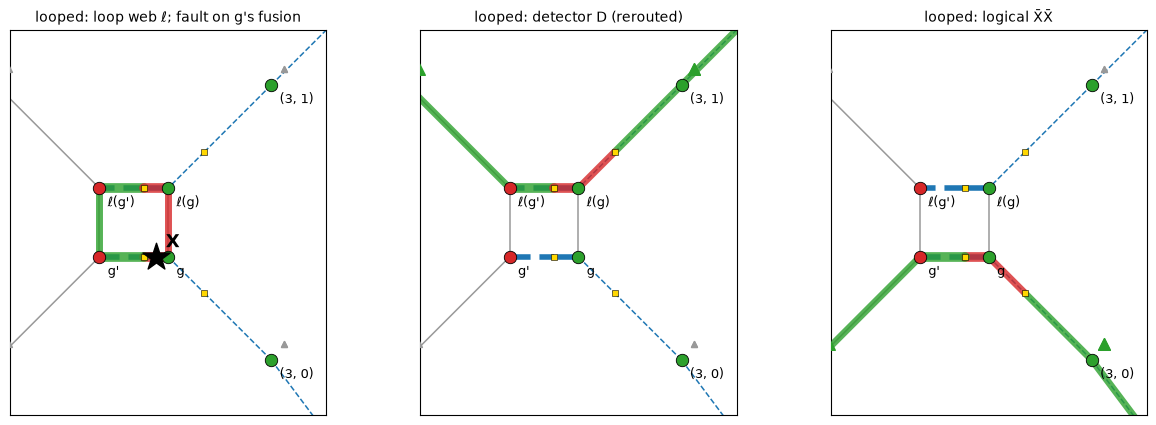

In [9]:
e = exp_looped
loop_web = next(k for k, w in enumerate(lsed.detectors[len(hsed.detectors):], len(hsed.detectors))
                if edge(lsed, g, ("loop", g)) in w.support())
f1 = (edge(e, g, ("split", g)), "X")
f2 = (edge(e, ("loop", g), ("loop", ("split", g))), "X")
rung = (edge(e, g, ("loop", g)), "X")
Zl = {q: (wire(e, q), "Z") for q in [(3, 0), (3, 1), (3, 2)]}
print("loop web ℓ is detector", loop_web)
rows = [("fusion g-g' fault", [f1]), ("Z(3,0) + X on rung", [Zl[3, 0], rung]),
        ("fusion ℓ(g)-ℓ(g') fault", [f2]), ("Z(3,1) + X on rung", [Zl[3, 1], rung]),
        ("Z(3,2)", [Zl[3, 2]]), ("fusion g-g' fault + Z(3,2)", [f1, Zl[3, 2]]),
        ("Z(3,0) Z(3,1) Z(3,2)", list(Zl.values()))]
for name, fs in rows:
    print(f"{name:28s} fires {syndrome(e, fs)[0]}, flips X̄X̄: {syndrome(e, fs)[1]}")
assert syndrome(e, [f1]) == syndrome(e, [Zl[3, 0], rung]) == ((loop_web,), True)
assert syndrome(e, [f1, Zl[3, 2]])[0] != ()
assert syndrome(e, list(Zl.values())) == ((), True)    # the column is still the weight-3 logical

bold = [x for l in looped.links if l.kind == "fusion" for x in l.interaction.edges]
fig, axes = row(3)
for ax, (name, w, fs) in zip(axes, [
        ("loop web ℓ; fault on g's fusion", looped.detectors[loop_web], [(edge(looped, g, ("split", g)), "X")]),
        ("detector D (rerouted)", looped.detectors[D_IDX], []),
        ("logical X̄X̄", looped.logicals[L_IDX], [])]):
    zoom(looped, w, fs, ax=ax, labels=labels_for(looped), bold=bold, box=((2.05, 3.2), (-0.2, 1.2)),
         title=f"looped: {name}")
plt.show()

## The other column

The boundary $Z$ checks on the right of the seam form a second column. Here the generator at the patch's outer edge, `w`, has weight 2: one seam leg (3,0) and one right-patch leg (4,0). The weight-4 check above it, `h`, has seam legs (3,1) and (3,2).

- `h` is the mirror image of `g`. A fault on its fusion equals $Z_{(3,1)}Z_{(3,2)}$, a hook on the *top* two seam qubits.
- `w` splits 1 | 1. A fault on its fusion carries a single seam leg, so it equals $Z_{(3,0)}$: one fault, one qubit, no new hook. Its inside half has only two legs, so `loopable` is false and `loop_boundary` leaves it alone.

The weight-2 logical in this column is $h$'s hook plus $Z_{(3,0)}$. `w`'s fusion fault can stand in for $Z_{(3,0)}$, because it is equivalent to it.

('gen', 3, 9) legs (qubit: inside S) {(3, 1): True, (4, 1): False, (3, 2): True, (4, 2): False} | loopable: True
('gen', 3, 7) legs (qubit: inside S) {(3, 0): True, (4, 0): False} | loopable: False
detector D2 = 99
h fusion fault         fires (99,), flips X̄X̄: False
Z(3,1) Z(3,2)          fires (99,), flips X̄X̄: False
w fusion fault         fires (99,), flips X̄X̄: True
Z(3,0)                 fires (99,), flips X̄X̄: True
h fusion + Z(3,0)      fires (), flips X̄X̄: True
h fusion + w fusion    fires (), flips X̄X̄: True


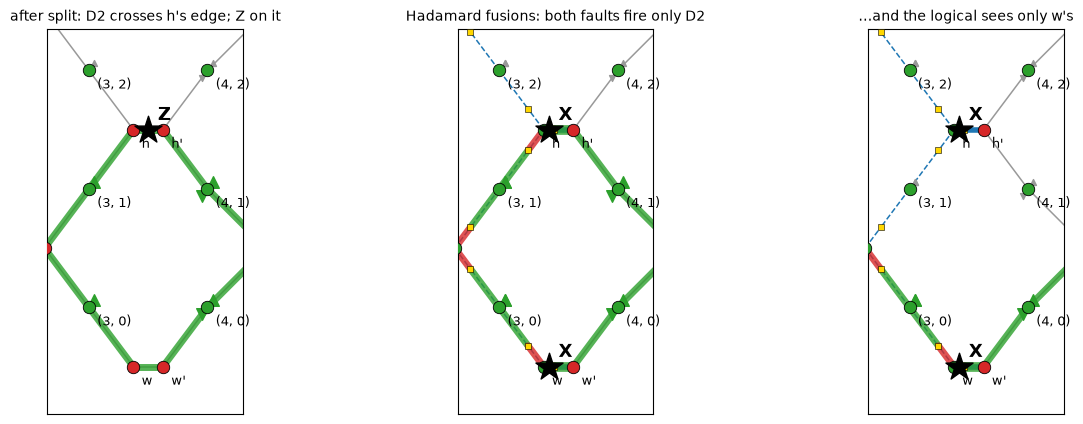

In [10]:
from dizx.transformations import loopable

h, w = ("gen", r0, 9), ("gen", r0, 7)
for x in (h, w):
    print(x, "legs (qubit: inside S)", {u[-1]: u in S0 for u in s.sed.graph.neighbors(x)},
          "| loopable:", loopable(hsed, ("split", x), x))
assert not loopable(hsed, ("split", w), w) and ("loop", w) not in lsed.types

e = exp_plain
Fh, Fw = (edge(e, h, ("split", h)), "X"), (edge(e, w, ("split", w)), "X")
Zp = {q: (wire(e, q), "Z") for q in [(3, 0), (3, 1), (3, 2)]}
D2_IDX = syndrome(e, [Fh])[0][0]
print("detector D2 =", D2_IDX)
rows = [("h fusion fault", [Fh]), ("Z(3,1) Z(3,2)", [Zp[3, 1], Zp[3, 2]]),
        ("w fusion fault", [Fw]), ("Z(3,0)", [Zp[3, 0]]),
        ("h fusion + Z(3,0)", [Fh, Zp[3, 0]]), ("h fusion + w fusion", [Fh, Fw])]
for name, fs in rows:
    print(f"{name:22s} fires {syndrome(e, fs)[0]}, flips X̄X̄: {syndrome(e, fs)[1]}")
assert syndrome(e, [Fh]) == syndrome(e, [Zp[3, 1], Zp[3, 2]]) == ((D2_IDX,), False)
assert syndrome(e, [Fw]) == syndrome(e, [Zp[3, 0]]) == ((D2_IDX,), True)
assert syndrome(e, [Fh, Zp[3, 0]]) == syndrome(e, [Fh, Fw]) == ((), True)

names = {h: "h", w: "w"}
BOX2 = ((2.65, 4.3), (-0.9, 2.35))
bold = [x for l in plain.links if l.kind == "fusion" for x in l.interaction.edges]
fig, axes = row(3)
zoom(split_sed, split_sed.detectors[D2_IDX], [(edge(split_sed, h, ("split", h)), "Z")], ax=axes[0],
     labels=labels_for(split_sed, names), box=BOX2, title="after split: D2 crosses h's edge; Z on it")
zoom(plain, plain.detectors[D2_IDX], [Fh, Fw], ax=axes[1], labels=labels_for(plain, names), bold=bold,
     box=BOX2, title="Hadamard fusions: both faults fire only D2")
zoom(plain, plain.logicals[L_IDX], [Fh, Fw], ax=axes[2], labels=labels_for(plain, names), bold=bold,
     box=BOX2, title="…and the logical sees only w's")
plt.show()

Looping `h` works exactly as for `g`: (3,1) and (3,2) end up on different spiders, and every crossing fault fires the loop web $\ell_h$. `w` keeps its single fusion, still equivalent to $Z_{(3,0)}$. Nothing pairs with it any more, because $h$'s fusion faults now also fire $\ell_h$.

loop web ℓ_h is detector 149 | h keeps [('H', ('gen', 3, 9), ('data', 3, 'Z', (3, 1)), 0), ('H', ('gen', 3, 9), ('split', ('gen', 3, 9)), 0), ('loop', ('gen', 3, 9))]
h fusion fault           fires (99, 149), flips X̄X̄: False
ℓ(h) fusion fault        fires (149,), flips X̄X̄: False
w fusion fault           fires (99,), flips X̄X̄: True
h fusion + Z(3,0)        fires (149,), flips X̄X̄: True
h fusion + w fusion      fires (149,), flips X̄X̄: True
ℓ(h) fusion + w fusion   fires (99, 149), flips X̄X̄: True
Z(3,0) Z(3,1) Z(3,2)     fires (), flips X̄X̄: True


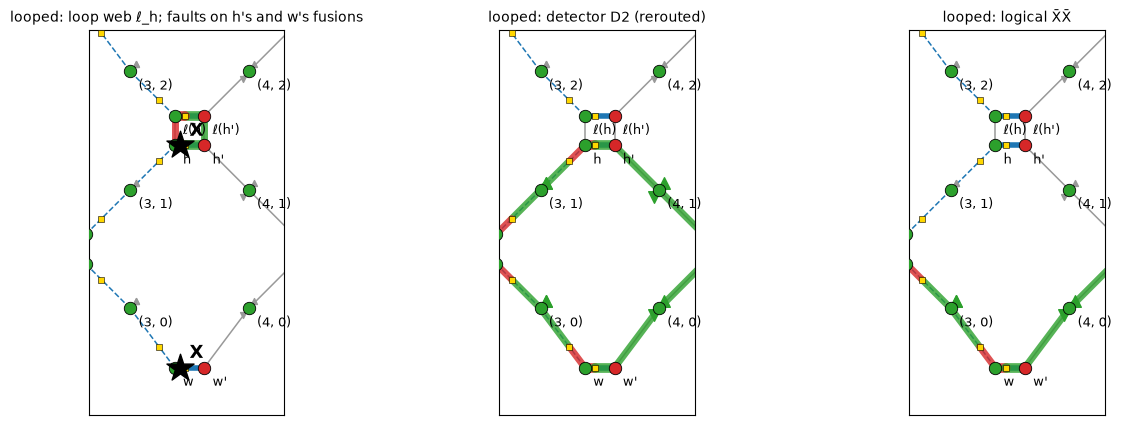

In [11]:
e = exp_looped
Fh, Fw = (edge(e, h, ("split", h)), "X"), (edge(e, w, ("split", w)), "X")
Fh2 = (edge(e, ("loop", h), ("loop", ("split", h))), "X")
rung = (edge(e, h, ("loop", h)), "X")
Zl = {q: (wire(e, q), "Z") for q in [(3, 0), (3, 1), (3, 2)]}
loop_h = next(k for k in range(len(hsed.detectors), len(lsed.detectors))
              if edge(lsed, h, ("loop", h)) in lsed.detectors[k].support())
print("loop web ℓ_h is detector", loop_h, "| h keeps", [u for u in lsed.graph.neighbors(h)])
rows = [("h fusion fault", [Fh]), ("ℓ(h) fusion fault", [Fh2]), ("w fusion fault", [Fw]),
        ("h fusion + Z(3,0)", [Fh, Zl[3, 0]]), ("h fusion + w fusion", [Fh, Fw]),
        ("ℓ(h) fusion + w fusion", [Fh2, Fw]), ("Z(3,0) Z(3,1) Z(3,2)", list(Zl.values()))]
for name, fs in rows:
    print(f"{name:24s} fires {syndrome(e, fs)[0]}, flips X̄X̄: {syndrome(e, fs)[1]}")
for fs in ([Fh], [Fh2], [rung]):
    assert loop_h in syndrome(e, fs)[0]
assert syndrome(e, [Fw]) == syndrome(e, [Zl[3, 0]])
for fs in ([Fh, Zl[3, 0]], [Fh, Fw], [Fh2, Fw]):
    assert syndrome(e, fs)[0] != ()

bold = [x for l in looped.links if l.kind == "fusion" for x in l.interaction.edges]
fig, axes = row(3)
for ax, (name, web, fs) in zip(axes, [
        ("loop web ℓ_h; faults on h's and w's fusions", looped.detectors[loop_h],
         [(edge(looped, h, ("split", h)), "X"), (edge(looped, w, ("split", w)), "X")]),
        ("detector D2 (rerouted)", looped.detectors[D2_IDX], []),
        ("logical X̄X̄", looped.logicals[L_IDX], [])]):
    zoom(looped, web, fs, ax=ax, labels=labels_for(looped, names), bold=bold, box=BOX2,
         title=f"looped: {name}")
plt.show()

## Distances

Edge level: the number of syndromes that single faults with different logical action share. Each is a weight-2 logical, and zero means the distance is at least 3. Circuit level: stim's `search_for_undetectable_logical_errors`, with noise on CX gates, measurements and fusions (none on the cluster's CZs), as in `tests/test_hybrid.py`.

In [12]:
def circuit_distance(c, p=1e-3):
    import stim
    noisy = stim.Circuit()
    for inst in c.flattened():
        if inst.name in ("M", "MX", "MPP"):
            noisy.append(inst.name, inst.targets_copy(), p)
            continue
        noisy.append(inst)
        if inst.name == "CX":
            noisy.append("DEPOLARIZE2", inst.targets_copy(), p)
    return len(noisy.search_for_undetectable_logical_errors(
        dont_explore_detection_event_sets_with_size_above=4, dont_explore_edges_with_degree_above=4,
        dont_explore_edges_increasing_symptom_degree=False))

print(f"{'realisation':14s}{'basis':>6s}{'edge weight-2 classes':>24s}{'circuit distance':>18s}")
for name, real in [("circuit-based", None), ("hybrid", plain), ("hybrid looped", looped)]:
    for basis in "ZX":
        exp = s.experiment(basis, realised=real)
        c = to_stim(exp, RotatedSurfaceCodeSchedule(s.merged))
        print(f"{name:14s}{basis:>6s}{len(ambiguous_classes(exp)):>24d}{circuit_distance(c):>18d}")

realisation    basis   edge weight-2 classes  circuit distance
circuit-based      Z                       0                 3
circuit-based      X                       0                 3
hybrid             Z                       0                 3
hybrid             X                       8                 2
hybrid looped      Z                       0                 3
hybrid looped      X                       0                 3


## Summary

- **The split** gives the boundary edge $f$ the non-matching parity over the inside legs. Every web that is odd on the two seam legs, here $D$ and $\bar X\bar X$, crosses $f$.
- **The Hadamard fusion** realises $f$ as one `XZ`/`ZX` fusion. One fault on it equals $Z$ on both seam legs: a vertical hook along the seam, in the direction of the minimum-weight $Z$ string. That string costs 2 faults instead of 3.
- **The other column** is the mirror image. There the hook is on the top two seam qubits, and the weight-2 generator `w` supplies the last qubit. `w`'s split is 1 | 1, so its fusion fault is a single seam qubit's worth. It cannot be looped and does not need to be.
- **The loop** gives each seam leg its own spider and its own crossing fusion. The two seam legs are no longer one fault apart, and the Bell-pair part of each crossing fault fires the loop web. The weight-2 classes disappear, and the circuit distance returns to 3.